In [1]:
# -*- coding: utf-8 -*-
from turtle import title
import numpy as numpy
import pandas as pd
import matplotlib.pyplot as plt
import tempfile
import os
from ansys.aedt.core import generate_unique_name
from ansys.aedt.core import Desktop, Hfss, constants
from ansys.aedt.core.modeler.cad.object_3d import Object3d

In [2]:
tmpfold = tempfile.gettempdir()

temp_folder = os.path.join(
    tmpfold,
    generate_unique_name("Antenna")
)

if not os.path.exists(temp_folder):
    os.mkdir(temp_folder)

non_graphical = os.getenv(
    "PYAEDT_NON_GRAPHICAL",
    "False"
).lower() in ("true", "1", "t")

d = Desktop(
    "2025.1",
    non_graphical=non_graphical,
    new_desktop=True
)

PyAEDT INFO: Python version 3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:42:04) [MSC v.1943 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.17.1.
PyAEDT INFO: Initializing new Desktop session.
PyAEDT INFO: Log on console is enabled.
PyAEDT INFO: Log on file C:\Users\LUIS~1.COS\AppData\Local\Temp\pyaedt_luis.costa_3d32fe1e-7582-43d5-a4c3-a688033f9477.log is enabled.
PyAEDT INFO: Log on AEDT is disabled.
PyAEDT INFO: Debug logger is disabled. PyAEDT methods will not be logged.
PyAEDT INFO: Launching PyAEDT with gRPC plugin.
PyAEDT INFO: New AEDT session is starting on gRPC port 62227.
PyAEDT INFO: Electronics Desktop started on gRPC port: 62227 after 18.006304264068604 seconds.
PyAEDT INFO: AEDT installation Path C:\Program Files\ANSYS Inc\v251\AnsysEM
PyAEDT INFO: Ansoft.ElectronicsDesktop.2025.1 version started with process ID 2408.


In [3]:
xsize = 30
E = 1.65
W = 25.5
L = 19.3
b = 1.4
lambdaG = 41
y0 = 6.5
ysize = L + (lambdaG/2) - y0 + 3

hfss = Hfss(solution_type="Modal")

hfss.modeler.model_units = "mm"

p = hfss.modeler.primitives

PyAEDT INFO: Python version 3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:42:04) [MSC v.1943 64 bit (AMD64)].
PyAEDT INFO: PyAEDT version 0.17.1.
PyAEDT INFO: Returning found Desktop session with PID 2408!
PyAEDT INFO: Project Project13 has been created.
PyAEDT INFO: No design is present. Inserting a new design.
PyAEDT INFO: Added design 'HFSS_ZXN' of type HFSS.
PyAEDT INFO: Aedt Objects correctly read
PyAEDT INFO: Modeler class has been initialized! Elapsed time: 0m 0sec


In [4]:
gnd = p.create_rectangle(
    constants.PLANE.XY,
    (-xsize/2 ,-ysize/2 ,0) ,
    (xsize, ysize),
    name="gnd"
)

substract = p.create_box(
    [-xsize/2 ,-ysize/2 ,0],
    [xsize, ysize, E],
    material="FR4_Epoxy",
    name="substract"
)

feed = p.create_rectangle(
    constants.PLANE.XY,
    (-b/2 ,-ysize/2 ,E) ,
    (b, lambdaG/2),
    name="feed"
) 

patch = p.create_rectangle(
    constants.PLANE.XY,
    (-W/2 ,-ysize/2+(lambdaG/2)-y0 ,E) ,
    (W, L),
    name="patch"
) 

cut = p.create_rectangle(
    constants.PLANE.XY,
    (-(b+0.8)/2 ,-ysize/2+(lambdaG/2)-y0 ,E) ,
    (b+0.8, y0),
    name="cut"
) 

p.subtract(patch, cut)
p.unite([patch, feed])
p.delete(cut)

port = p.create_rectangle(
    constants.PLANE.ZX,
    (-b/2 ,-ysize/2 ,0) ,
    (E, b),
    name="port1"
)

hfss.assign_perfect_e(
    patch.name
)

hfss.assign_perfect_e(
    gnd.name
)

hfss.change_material_override()

hfss.lumped_port(
    assignment=port.name,                 
    reference=port,
    integration_line=hfss.AxisDir.ZNeg,    
    impedance=50,
    name=generate_unique_name("port1"),
    renormalize=False,
    terminals_rename=False
)

PyAEDT INFO: Materials class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Union of 2 objects has been executed.
PyAEDT INFO: Parsing design objects. This operation can take time
PyAEDT INFO: Refreshing bodies from Object Info
PyAEDT INFO: Bodies Info Refreshed Elapsed time: 0m 0sec
PyAEDT INFO: 3D Modeler objects parsed. Elapsed time: 0m 0sec
PyAEDT INFO: Deleted 1 Objects: cut.
PyAEDT INFO: Boundary Perfect E PerfectE_patch has been created.
PyAEDT INFO: Boundary Perfect E PerfectE_gnd has been created.
PyAEDT INFO: Enabling Material Override
PyAEDT INFO: Boundary Lumped Port port1_ODFA4K has been created.


In [5]:
my_plot = hfss.plot(show=False, plot_air_objects=False)
my_plot.show_axes = False
my_plot.show_grid = False
my_plot.isometric_view = True
my_plot.plot(
    os.path.join(hfss.working_directory, "AntennaPatchGap.jpg")    
)

setup = hfss.create_setup("MySetup")

PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: PostProcessor class has been initialized! Elapsed time: 0m 0sec
PyAEDT INFO: Post class has been initialized! Elapsed time: 0m 0sec


Widget(value='<iframe src="http://localhost:62271/index.html?ui=P_0x1e7de8859c0_0&reconnect=auto" class="pyvis…

In [6]:
def SingleFrequency(
    freq,
    maxPasses,
    maxDeltaS= 0.01,
    name="MySetup"
):
    hfss.create_open_region(frequency=freq)
    setup.props["Frequency"] = freq
    setup.props["MaximumPasses"] = maxPasses
    setup.props["MaxDeltaS"] =maxDeltaS
    setup.props["UseIterativeSolver"] = True
    setup.props["SaveRadFieldsOnly"] = True
    setup.props["RadiationSetup"] = "3D"
    setup.props["ComputeFarFields"] = True

SingleFrequency("3.5GHz", 30,0.02)



PyAEDT INFO: Open Region correctly created.
PyAEDT INFO: Project Project13 Saved correctly


In [7]:
def LinearCountSweep(
    fStart,
    fStop,
    freqPonts=401,
    units="GHz",
    saveFields=True,
    saveRadFields=True
):
    sweep = hfss.create_linear_count_sweep(
        setup=setup.name,
        units=units,
        start_frequency=fStart,
        stop_frequency=fStop,
        num_of_freq_points = freqPonts,
        name= "sweep",
        sweep_type="Interpolating",
        save_fields=saveFields,
        save_rad_fields=saveRadFields
    )
LinearCountSweep(1.0,5.0)


PyAEDT INFO: Parsing C:/Users/luis.costa/Documents/Ansoft/Project13.aedt.
PyAEDT INFO: File C:/Users/luis.costa/Documents/Ansoft/Project13.aedt correctly loaded. Elapsed time: 0m 0sec
PyAEDT INFO: aedt file load time 0.12594270706176758
PyAEDT INFO: Linear count sweep sweep has been correctly created.


In [8]:
def SaveAnalyseSetup(
    nameFolder= "AntennaPatch.aedt",
    setup="MySetup"
):
    hfss.save_project(os.path.join(temp_folder, nameFolder))
    hfss.analyze_setup(setup)

SaveAnalyseSetup("AntennaPatchGap.aedt")

PyAEDT INFO: Project AntennaPatchGap Saved correctly
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Solving design setup MySetup
PyAEDT INFO: Key Desktop/ActiveDSOConfigurations/HFSS correctly changed.
PyAEDT INFO: Design setup MySetup solved correctly in 0.0h 1.0m 27.0s


In [9]:

solutions = hfss.post.get_solution_data(
    expressions=hfss.get_traces_for_plot(category="dB(S")
)

solutions.enable_pandas_output = True

S_Real = solutions._init_solution_data_real()
index = 0
S_real1 = S_Real[list(S_Real.keys())[index]]
listaReal = []
listaReal2 = []
dataVazioGap = {}
dfRealGap = pd.DataFrame(dataVazioGap)
for i,c in S_real1.items():
    #a = i[0]
    #listaReal.append(a)
    listaReal.append(float(i[0]))
    #c=S_real1[i]
    listaReal2.append(float(c))
dfRealGap.insert(0, "Frequency [GHz]", listaReal, True)
dfRealGap.insert(1, "|$S_{11}$| [dB]", listaReal2, True)
indexValueMin = dfRealGap['|$S_{11}$| [dB]'].idxmin()

dfRealGap.to_csv('S11_Gap.csv')

PyAEDT INFO: Solution Data Correctly Loaded.


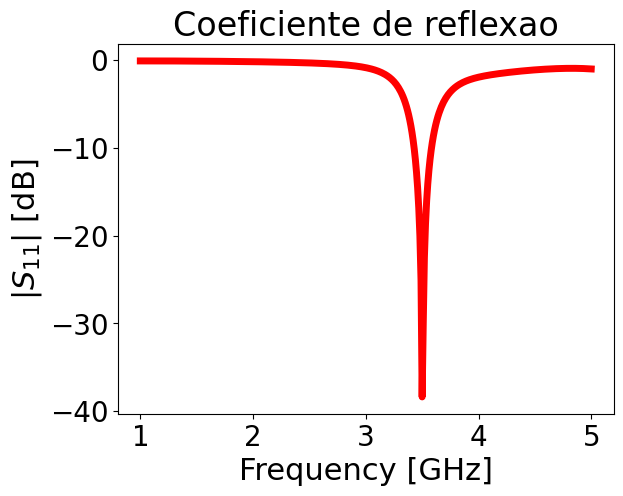

In [10]:
def Grafico(
    df,
    title,
    nameX='Frequency [GHz]',
    nameY='Result',
    colorGraf='red'
):
    valorEixoY = df[nameY].to_numpy()
    valorEixoX = df[nameX].to_numpy()
    fig, ax = plt.subplots()
    ax.plot(valorEixoX, valorEixoY, color='red', linewidth = 5)
    ax.set_xlabel(nameX, fontsize = 22)
    ax.set_ylabel(nameY, fontsize = 22)
    plt.tick_params(axis='both', which='major', labelsize=20)
    plt.title(title, fontsize=24)
    plt.show()

Grafico(
    dfRealGap,
    "Coeficiente de reflexao",
    "Frequency [GHz]",
    "|$S_{11}$| [dB]",
)

In [11]:
new_report = hfss.post.reports_by_category.far_field(
    "GainTotal",
    hfss.nominal_adaptive,
    "3D"
)
variations = hfss.available_variations.nominal_w_values_dict
variations["Theta"] = ["All"]
variations["Phi"] = ["All"]
variations["Freq"] = ["3.5GHz"]

In [ ]:
new_report.primary_sweep ="Theta"
new_report.secondary_sweep ="Phi"
new_report.far_field_sphere = "3D"
new_report.variations = variations
solutions = new_report.get_solution_data()

PyAEDT INFO: Solution Data Correctly Loaded.


[4.081337660374426,
 4.077630893642062,
 4.06480027581591,
 4.042894048222871,
 4.011982885528048,
 3.9721591376184753,
 3.923535976150547,
 3.8662464564929393,
 3.8004425060619758,
 3.7262938506006704,
 3.6439868907842,
 3.5537235425754248,
 3.4557200558865353,
 3.350205827171462,
 3.2374222223964377,
 3.1176214272245026,
 2.9910653410217836,
 2.8580245302922576,
 2.71877725525292,
 2.5736085804026896,
 2.422809576102188,
 2.2666766134191443,
 2.105510748924716,
 1.9396171899390184,
 1.7693048241792106,
 1.5948857911853656,
 1.4166750666722148,
 1.234990025506302,
 1.050149944793495,
 0.8624754060374986,
 0.6722875549247243,
 0.47990717937341154,
 0.28565357132920527,
 0.08984314554391742,
 -0.10721220076531301,
 -0.3052069900897532,
 -0.5038443155894309,
 -0.7028382102034851,
 -0.9019161845619394,
 -1.1008218653692636,
 -1.2993176476433665,
 -1.4971872576310563,
 -1.6942381094270034,
 -1.8903033283017578,
 -2.0852433083998085,
 -2.27894667255112,
 -2.47133050799586,
 -2.6623397641602

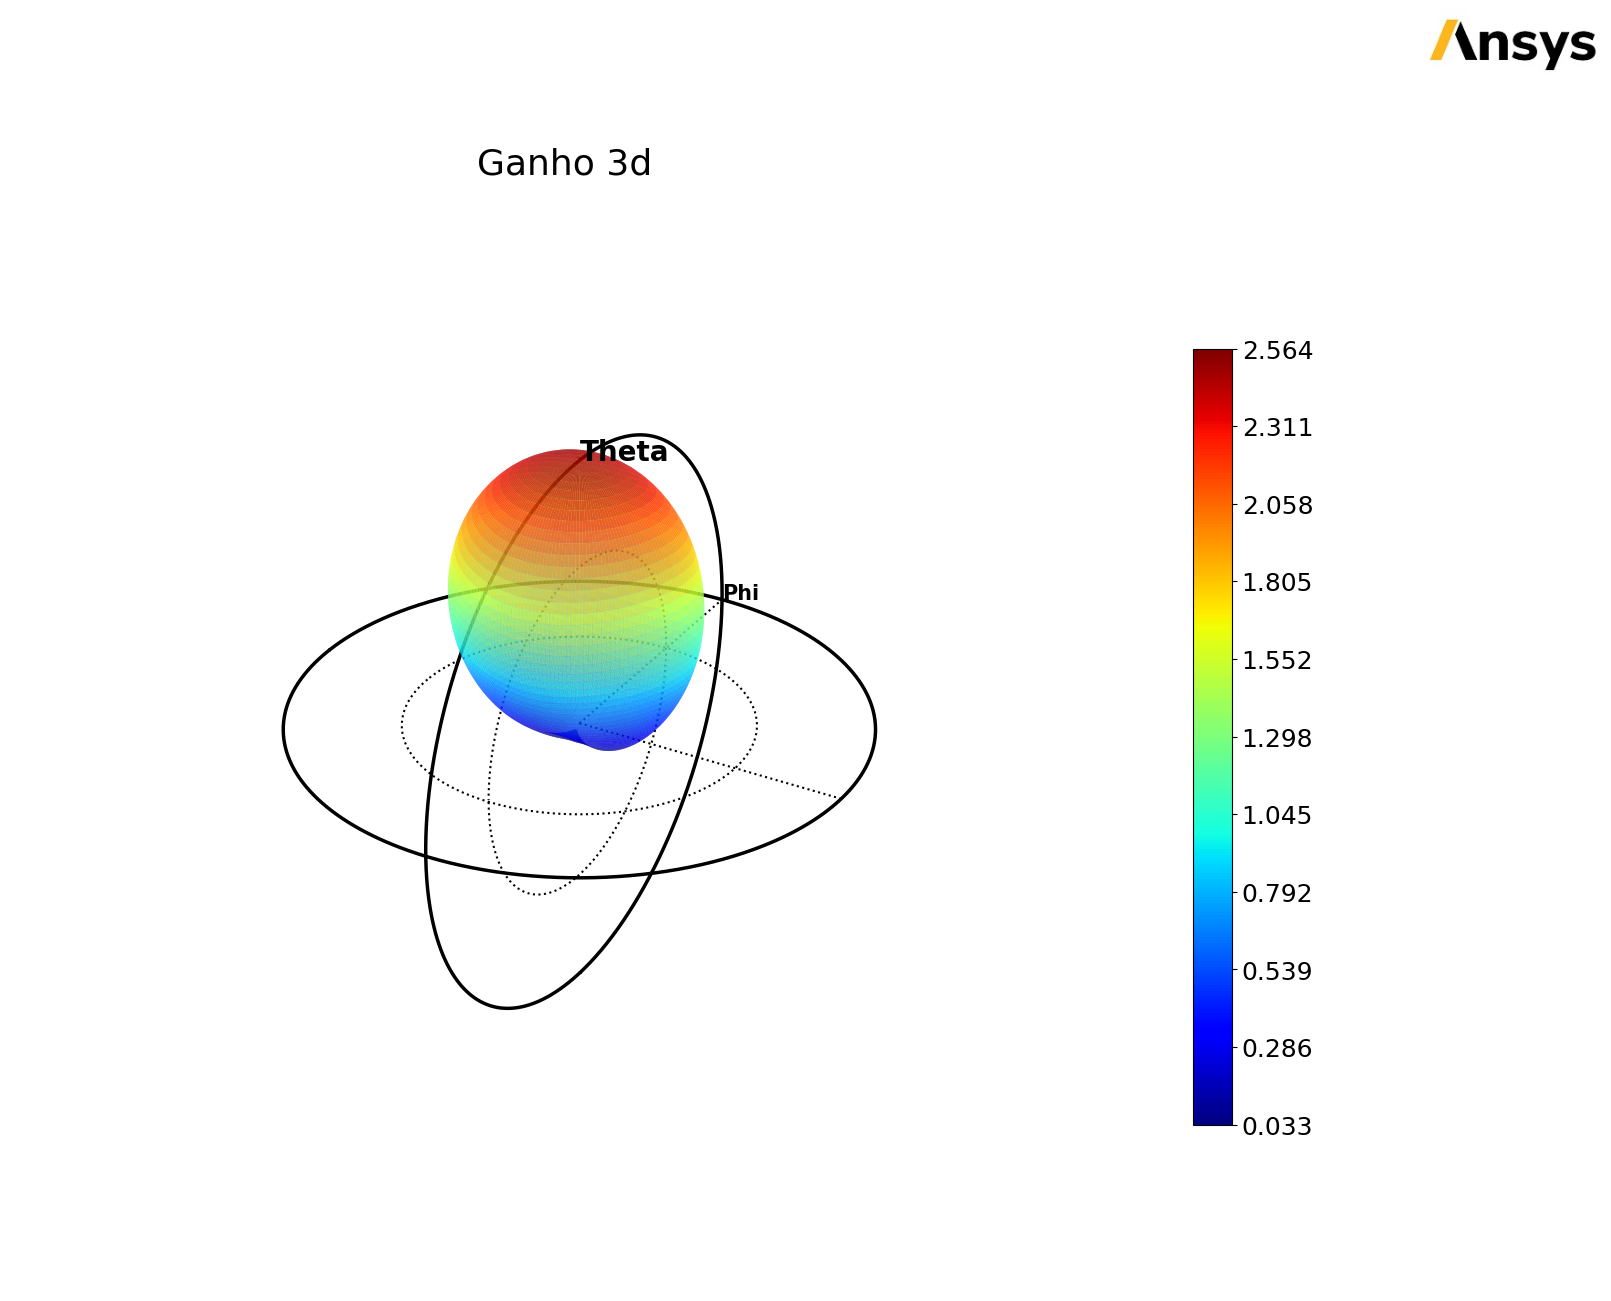

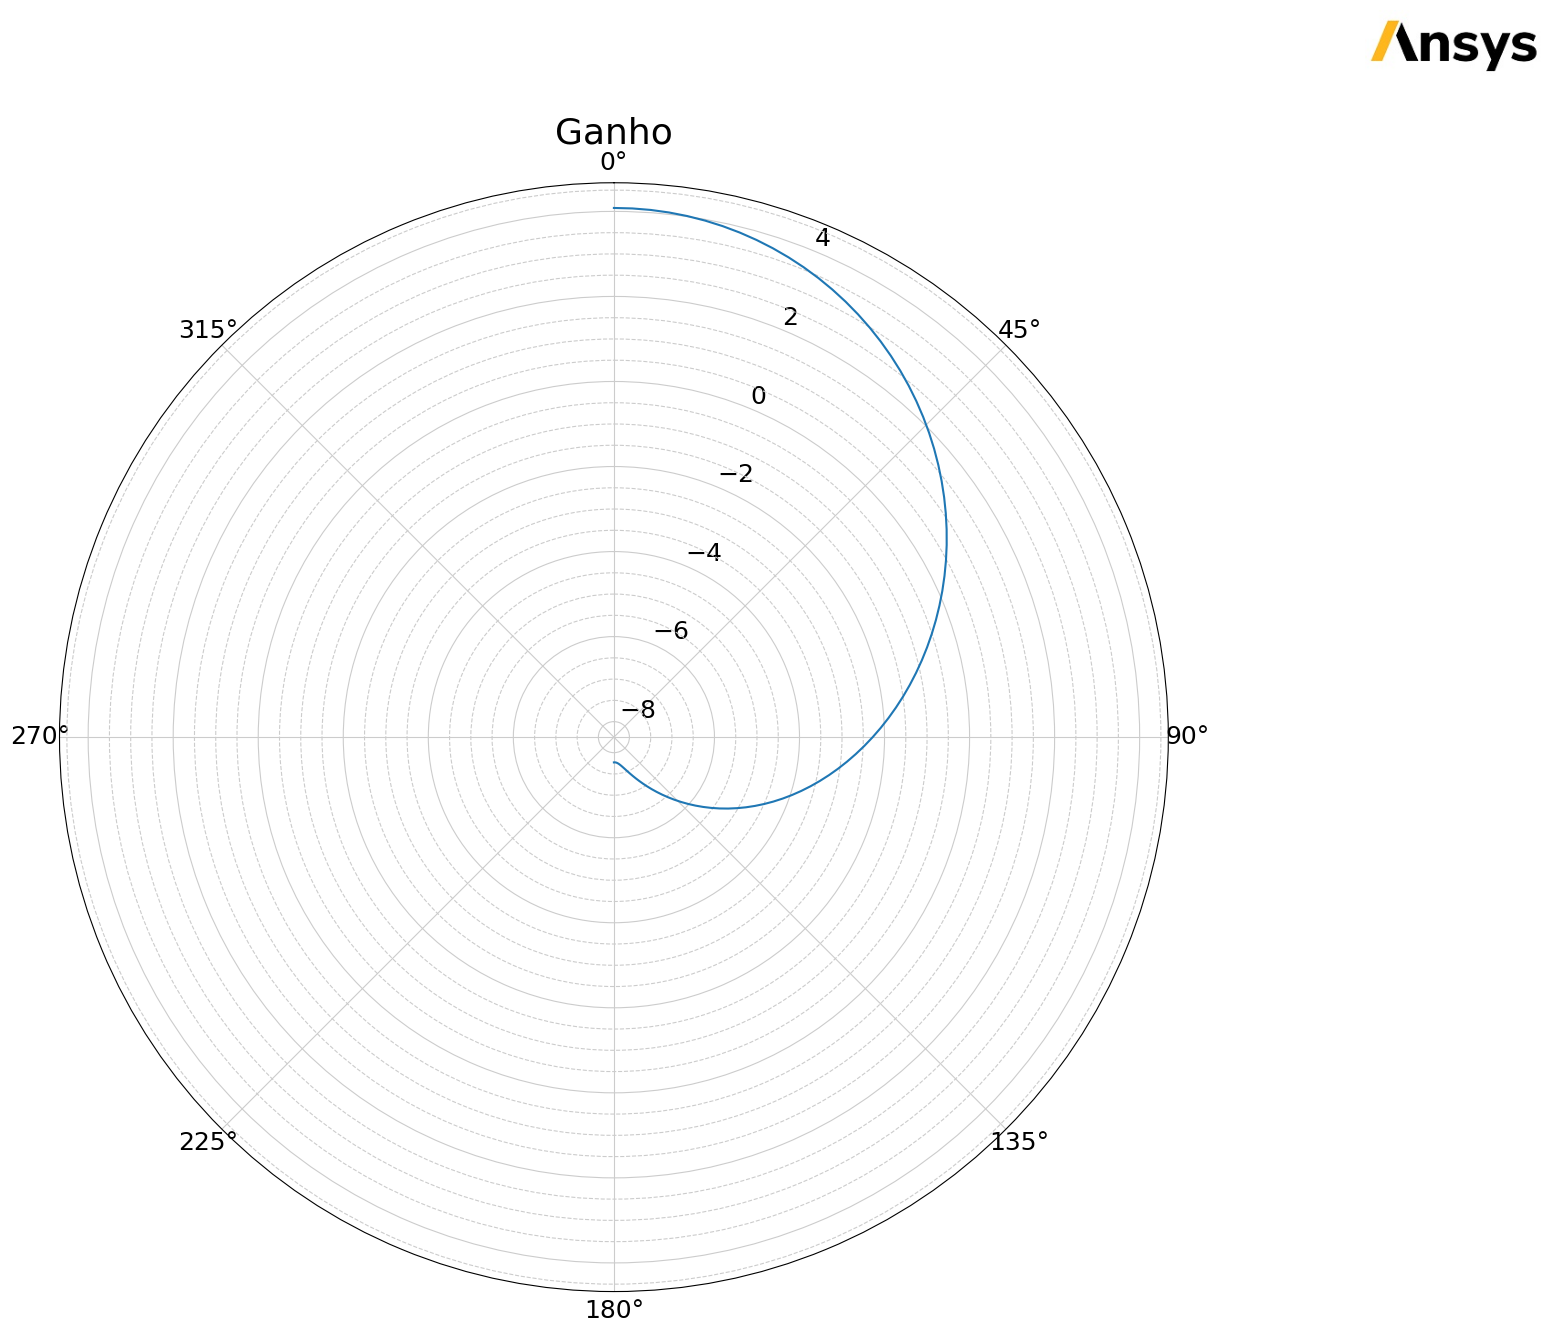

In [13]:
solutions.plot_3d(title="Ganho 3d")

solutions.plot(
     formula="db10",
     is_polar=True,
     show_legend=False,
     title="Ganho"
)

solutions.data_db10()

In [14]:
#d.release_desktop()